# Notebook 03 – Modelling & Hyperparameter Tuning

**Purpose:** Train all models, tune the best ones with Optuna, build a stacking
ensemble, and save all fitted pipelines.

**Primary metric:** PR-AUC (average_precision_score)  
**Why PR-AUC:** With 26.5% churn, ROC-AUC can be misleadingly high even for
poor models because the large negative class inflates TN. PR-AUC focuses on
the minority (churn) class and penalises false negatives more severely.

**Tuning:** Optuna TPE sampler, 50 trials, 5-fold StratifiedKFold.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import joblib, optuna
from pathlib import Path

from data_utils import load_raw, make_splits, class_balance
from models import (
    get_baseline_pipelines, get_advanced_pipelines,
    get_stacking_pipeline, tune_xgboost, tune_lightgbm,
    build_tuned_pipeline, cv_score, RANDOM_STATE
)

FIG_DIR    = Path('../reports/figures')
RES_DIR    = Path('../reports/results')
MODELS_DIR = Path('../models')
RES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['savefig.dpi'] = 300

def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=300, bbox_inches='tight')
    plt.show()

## 1. Load Data & Compute Class Ratio

In [2]:
df = load_raw()
X_train, X_val, X_test, y_train, y_val, y_test = make_splits(df)

balance = class_balance(y_train)
pos_weight = round(balance['n_no_churn'] / balance['n_churn'], 4)
print(f'Train balance: {balance}')
print(f'scale_pos_weight for XGBoost: {pos_weight}')

Train balance: {'n_no_churn': 3104, 'n_churn': 1121, 'churn_rate': 26.53}
scale_pos_weight for XGBoost: 2.769


## 2. Why Gradient Boosting?

| Criterion | Gradient Boosting | Logistic Regression | Neural Network |
|-----------|:-----------------:|:-------------------:|:--------------:|
| Mixed numeric + categorical | ✅ | ⚠️ needs careful encoding | ✅ |
| Non-linear interactions | ✅ automatic | ❌ manual feature crosses | ✅ |
| Handles imbalance natively | ✅ scale_pos_weight | ⚠️ class_weight only | ⚠️ |
| Interpretable (SHAP) | ✅ TreeExplainer (exact) | ✅ coefficients | ❌ approximate |
| Performance on tabular data | ✅ SOTA (Grinsztajn et al. 2022) | ❌ | ⚠️ needs large data |
| Training speed (7k rows) | ✅ fast | ✅ fast | ❌ slow |

**References:** Chen & Guestrin (2016) XGBoost; Ke et al. (2017) LightGBM;
Grinsztajn et al. (2022) "Why tree-based models still outperform deep learning
on tabular data" (NeurIPS).

## 3. Baseline Models – CV Scores

In [3]:
baselines = get_baseline_pipelines()
baseline_cv = {}

for name, pipe in baselines.items():
    mean, std = cv_score(pipe, X_train, y_train)
    baseline_cv[name] = {'cv_prauc_mean': mean, 'cv_prauc_std': std}
    print(f'{name:25s}  PR-AUC = {mean:.4f} ± {std:.4f}')

Dummy_MostFrequent         PR-AUC = 0.2653 ± 0.0005


LogisticRegression         PR-AUC = 0.6656 ± 0.0372


DecisionTree               PR-AUC = 0.5976 ± 0.0210


## 4. Advanced Models – CV Scores (default hyperparameters)

In [4]:
advanced = get_advanced_pipelines(pos_weight=pos_weight)
advanced_cv = {}

for name, pipe in advanced.items():
    mean, std = cv_score(pipe, X_train, y_train)
    advanced_cv[name] = {'cv_prauc_mean': mean, 'cv_prauc_std': std}
    print(f'{name:25s}  PR-AUC = {mean:.4f} ± {std:.4f}')

RandomForest               PR-AUC = 0.6267 ± 0.0100


XGBoost                    PR-AUC = 0.6120 ± 0.0225


LightGBM                   PR-AUC = 0.6128 ± 0.0217


CatBoost                   PR-AUC = nan ± nan


In [5]:
# Combined CV comparison table
all_cv = {**baseline_cv, **advanced_cv}
cv_df = pd.DataFrame(all_cv).T.sort_values('cv_prauc_mean', ascending=False)
cv_df.to_csv(RES_DIR / 'cv_scores_default.csv')
print(cv_df.to_string())

                    cv_prauc_mean  cv_prauc_std
LogisticRegression         0.6656        0.0372
RandomForest               0.6267        0.0100
LightGBM                   0.6128        0.0217
XGBoost                    0.6120        0.0225
DecisionTree               0.5976        0.0210
Dummy_MostFrequent         0.2653        0.0005
CatBoost                      NaN           NaN


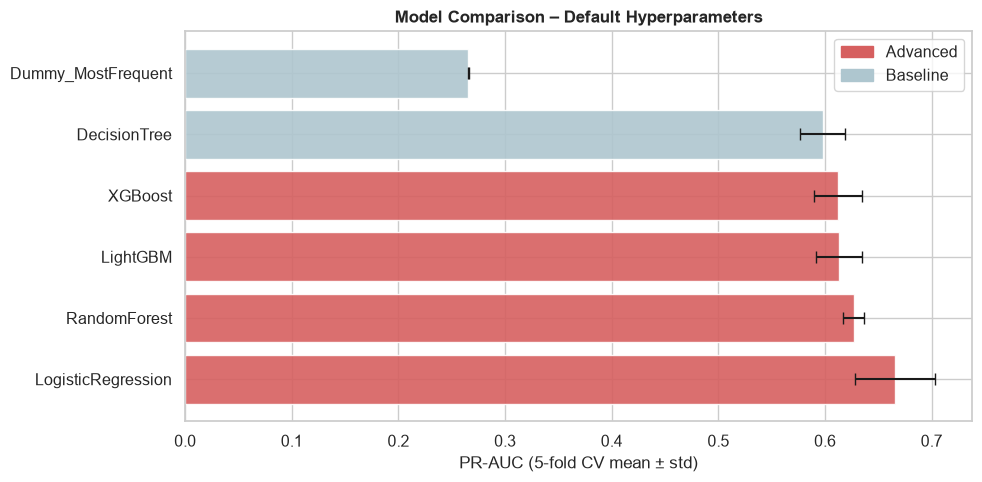

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#aec6cf'] * len(baseline_cv) + ['#D65F5F'] * len(advanced_cv)
bars = ax.barh(
    cv_df.index,
    cv_df['cv_prauc_mean'],
    xerr=cv_df['cv_prauc_std'],
    color=colors[::-1],
    capsize=4, edgecolor='white', alpha=0.9
)
ax.set_xlabel('PR-AUC (5-fold CV mean ± std)')
ax.set_title('Model Comparison – Default Hyperparameters', fontweight='bold')
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#D65F5F', label='Advanced'),
    Patch(color='#aec6cf', label='Baseline')
])
plt.tight_layout()
savefig('13_cv_comparison_default.png')

## 5. Optuna Tuning – XGBoost (50 trials)

In [7]:
print('Tuning XGBoost with Optuna (50 trials)...')
xgb_study = tune_xgboost(X_train, y_train, n_trials=50, pos_weight=pos_weight)
print(f'\nBest XGBoost PR-AUC: {xgb_study.best_value:.4f}')
print('Best params:')
for k, v in xgb_study.best_params.items():
    print(f'  {k}: {v}')

Tuning XGBoost with Optuna (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]


Best XGBoost PR-AUC: 0.6694
Best params:
  n_estimators: 536
  max_depth: 4
  learning_rate: 0.012413189635294229
  subsample: 0.7243929286862649
  colsample_bytree: 0.6625916610133735
  min_child_weight: 8
  gamma: 3.1877873567760657
  reg_alpha: 1.774425485152653
  reg_lambda: 2.888859700647797


## 6. Optuna Tuning – LightGBM (50 trials)

In [8]:
print('Tuning LightGBM with Optuna (50 trials)...')
lgbm_study = tune_lightgbm(X_train, y_train, n_trials=50)
print(f'\nBest LightGBM PR-AUC: {lgbm_study.best_value:.4f}')
print('Best params:')
for k, v in lgbm_study.best_params.items():
    print(f'  {k}: {v}')

Tuning LightGBM with Optuna (50 trials)...


  0%|          | 0/50 [00:00<?, ?it/s]


Best LightGBM PR-AUC: 0.6685
Best params:
  n_estimators: 410
  num_leaves: 41
  learning_rate: 0.026440616281000796
  max_depth: 3
  min_child_samples: 27
  subsample: 0.9046079494733414
  colsample_bytree: 0.9424161492558045
  reg_alpha: 1.440721489250485
  reg_lambda: 3.6258060953460536


## 7. Optuna Visualisations

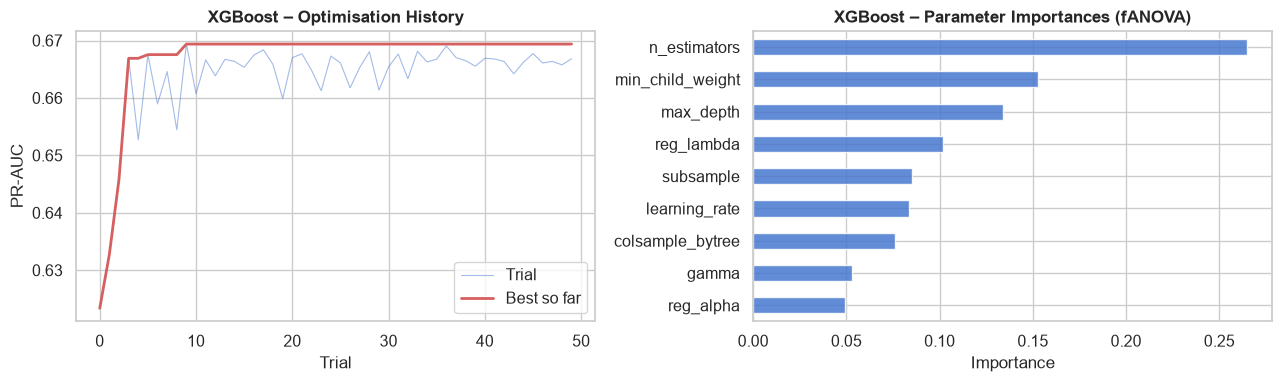

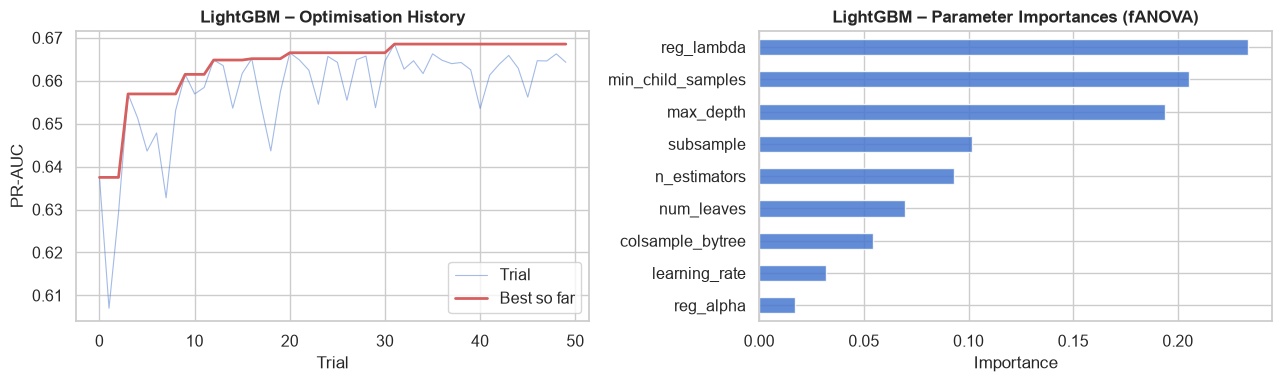

In [9]:
# Optuna has built-in plotly visualisations; we also make matplotlib versions
# for the report (no plotly dependency in static figures)

for study, name in [(xgb_study, 'XGBoost'), (lgbm_study, 'LightGBM')]:
    trials_df = study.trials_dataframe()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Optimisation history
    axes[0].plot(trials_df['number'], trials_df['value'],
                 alpha=0.5, color='#4878CF', linewidth=0.8, label='Trial')
    best_so_far = trials_df['value'].cummax()
    axes[0].plot(trials_df['number'], best_so_far,
                 color='#D65F5F', linewidth=2, label='Best so far')
    axes[0].set_xlabel('Trial')
    axes[0].set_ylabel('PR-AUC')
    axes[0].set_title(f'{name} – Optimisation History', fontweight='bold')
    axes[0].legend()

    # Parameter importances (Optuna FAnova)
    try:
        importances = optuna.importance.get_param_importances(study)
        imp_series = pd.Series(importances).sort_values()
        imp_series.plot(kind='barh', ax=axes[1], color='#4878CF', alpha=0.85)
        axes[1].set_title(f'{name} – Parameter Importances (fANOVA)', fontweight='bold')
        axes[1].set_xlabel('Importance')
    except Exception:
        axes[1].text(0.5, 0.5, 'Not enough trials for fANOVA',
                     ha='center', va='center', transform=axes[1].transAxes)

    plt.tight_layout()
    savefig(f'14_optuna_{name.lower()}.png')

## 8. Build Tuned Pipelines & Validate on Val Set

In [10]:
from sklearn.metrics import average_precision_score, roc_auc_score

xgb_tuned  = build_tuned_pipeline('XGBoost',  xgb_study.best_params,  pos_weight)
lgbm_tuned = build_tuned_pipeline('LightGBM', lgbm_study.best_params)

val_results = {}
for name, pipe in [('XGBoost_Tuned', xgb_tuned), ('LightGBM_Tuned', lgbm_tuned)]:
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_val)[:, 1]
    val_results[name] = {
        'val_prauc':  round(average_precision_score(y_val, prob), 4),
        'val_rocauc': round(roc_auc_score(y_val, prob), 4),
    }
    print(f'{name:20s}  PR-AUC={val_results[name]["val_prauc"]}  ROC-AUC={val_results[name]["val_rocauc"]}')

XGBoost_Tuned         PR-AUC=0.6755  ROC-AUC=0.859


LightGBM_Tuned        PR-AUC=0.6782  ROC-AUC=0.8574


## 9. Stacking Ensemble

In [11]:
from features import build_tree_pipeline
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print('Training stacking ensemble...')
stacking = get_stacking_pipeline(X_train, y_train, pos_weight=pos_weight)
stacking.fit(X_train, y_train)

stack_prob = stacking.predict_proba(X_val)[:, 1]
val_results['Stacking'] = {
    'val_prauc':  round(average_precision_score(y_val, stack_prob), 4),
    'val_rocauc': round(roc_auc_score(y_val, stack_prob), 4),
}
print(f'Stacking  PR-AUC={val_results["Stacking"]["val_prauc"]}  ROC-AUC={val_results["Stacking"]["val_rocauc"]}')

Training stacking ensemble...


Stacking  PR-AUC=0.6288  ROC-AUC=0.8359


## 10. Best Params Table (for Report)

In [12]:
params_rows = []
for param, val in xgb_study.best_params.items():
    params_rows.append({'model': 'XGBoost', 'parameter': param, 'best_value': val})
for param, val in lgbm_study.best_params.items():
    params_rows.append({'model': 'LightGBM', 'parameter': param, 'best_value': val})

params_df = pd.DataFrame(params_rows)
params_df.to_csv(RES_DIR / 'best_hyperparameters.csv', index=False)
print(params_df.to_string(index=False))

   model         parameter  best_value
 XGBoost      n_estimators  536.000000
 XGBoost         max_depth    4.000000
 XGBoost     learning_rate    0.012413
 XGBoost         subsample    0.724393
 XGBoost  colsample_bytree    0.662592
 XGBoost  min_child_weight    8.000000
 XGBoost             gamma    3.187787
 XGBoost         reg_alpha    1.774425
 XGBoost        reg_lambda    2.888860
LightGBM      n_estimators  410.000000
LightGBM        num_leaves   41.000000
LightGBM     learning_rate    0.026441
LightGBM         max_depth    3.000000
LightGBM min_child_samples   27.000000
LightGBM         subsample    0.904608
LightGBM  colsample_bytree    0.942416
LightGBM         reg_alpha    1.440721
LightGBM        reg_lambda    3.625806


## 11. Save All Fitted Pipelines

In [13]:
# Fit baselines and advanced defaults on full training set before saving
all_fitted = {}

for name, pipe in {**get_baseline_pipelines(),
                   **get_advanced_pipelines(pos_weight)}.items():
    pipe.fit(X_train, y_train)
    all_fitted[name] = pipe

all_fitted['XGBoost_Tuned']  = xgb_tuned
all_fitted['LightGBM_Tuned'] = lgbm_tuned
all_fitted['Stacking']       = stacking

# Determine best single model by val PR-AUC
best_name = max(val_results, key=lambda k: val_results[k]['val_prauc'])
print(f'Best model on validation set: {best_name}')

# Save all pipelines
for name, pipe in all_fitted.items():
    joblib.dump(pipe, MODELS_DIR / f'pipeline_{name}.joblib')

# Save best pipeline separately for easy loading in later notebooks
best_pipeline = all_fitted[best_name]
artifact = {
    'pipeline':      best_pipeline,
    'model_name':    best_name,
    'best_params':   xgb_study.best_params if 'XGBoost' in best_name else lgbm_study.best_params,
    'val_prauc':     val_results[best_name]['val_prauc'],
    'val_rocauc':    val_results[best_name]['val_rocauc'],
    'pos_weight':    pos_weight,
}
joblib.dump(artifact, MODELS_DIR / 'best_pipeline.joblib')
joblib.dump(all_fitted, MODELS_DIR / 'all_pipelines.joblib')

print('\nSaved pipelines:')
for f in sorted(MODELS_DIR.glob('pipeline_*.joblib')):
    print(f'  {f.name}')
print('  best_pipeline.joblib')
print('  all_pipelines.joblib')

Best model on validation set: LightGBM_Tuned



Saved pipelines:
  pipeline_CatBoost.joblib
  pipeline_DecisionTree.joblib
  pipeline_Dummy_MostFrequent.joblib
  pipeline_LightGBM.joblib
  pipeline_LightGBM_Tuned.joblib
  pipeline_LogisticRegression.joblib
  pipeline_RandomForest.joblib
  pipeline_Stacking.joblib
  pipeline_XGBoost.joblib
  pipeline_XGBoost_Tuned.joblib
  best_pipeline.joblib
  all_pipelines.joblib


## 12. CV Scores Summary Table (all models)

In [14]:
tuned_cv = {
    'XGBoost_Tuned':  {'cv_prauc_mean': round(xgb_study.best_value, 4),  'cv_prauc_std': 0.0},
    'LightGBM_Tuned': {'cv_prauc_mean': round(lgbm_study.best_value, 4), 'cv_prauc_std': 0.0},
}
full_cv_df = pd.DataFrame({**all_cv, **tuned_cv}).T.sort_values('cv_prauc_mean', ascending=False)
full_cv_df.to_csv(RES_DIR / 'cv_scores_all_models.csv')
print(full_cv_df.to_string())
print('\nNotebook 03 complete.')

                    cv_prauc_mean  cv_prauc_std
XGBoost_Tuned              0.6694        0.0000
LightGBM_Tuned             0.6685        0.0000
LogisticRegression         0.6656        0.0372
RandomForest               0.6267        0.0100
LightGBM                   0.6128        0.0217
XGBoost                    0.6120        0.0225
DecisionTree               0.5976        0.0210
Dummy_MostFrequent         0.2653        0.0005
CatBoost                      NaN           NaN

Notebook 03 complete.
